# Análisis de Germana con BERTopic

Se comparan las tres configuraciones ya ajustadas, sin modificar las stopwords, los embeddings ni las asignaciones. No se ejecuta el bonus ni se llama a una API de LLM. Los nombres y juicios cualitativos son una interpretación asistida por Codex, declarada como uso de IA; no representan una comparación BERTopic vs. LLM ni una evaluación independiente.

La configuración A se toma como principal por recuperar temas concretos que B/C reúnen en un grupo amplio. Esta selección es cualitativa, no un resultado de validación supervisada. Se revisan tres representantes automáticos por tópico en A/B, los mismos ejemplos de B para C, dos párrafos adicionales por tópico de A elegidos con semilla 17 y diez outliers de A con semilla 42. No se afirma haber leído y validado los 1,177 párrafos individualmente. Las categorías de coherencia son juicios orientativos, no métricas calculadas.


In [1]:
from pathlib import Path
import ast
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
from IPython.display import display, Image

BASE = Path.cwd() if (Path.cwd() / "germana.txt").exists() else Path.cwd() / "BERTopic"
ROOT = BASE / "resultados"
OUT = ROOT / "analisis"
OUT.mkdir(exist_ok=True)
labels = json.loads((OUT / "nombres_y_criterios.json").read_text())
assignments = pd.read_csv(ROOT / "configuraciones" / "asignaciones.csv")
segments = pd.read_csv(ROOT / "segmentos.csv")
df = assignments.merge(segments.drop(columns=["texto", "capitulo"]), on="segmento_id", validate="one_to_one")
assert len(df) == len(segments) == 1177
assert df.segmento_id.tolist() == segments.segmento_id.tolist()
embeddings = np.load(ROOT / "embeddings_minilm.npy")
assert len(embeddings) == len(df)
comparison = pd.read_csv(ROOT / "configuraciones" / "comparacion.csv")
df["inicia_dialogo"] = df.texto.str.startswith("--")
figures = []


In [2]:
tables, representatives = {}, {}
for config in ["A", "B", "C"]:
    info = pd.read_csv(ROOT / "configuraciones" / config / "topic_info.csv")
    info["Nombre_propio"] = info.Topic.map(lambda t: labels[config][str(t)][0])
    info["Coherencia_cualitativa"] = info.Topic.map(lambda t: labels[config][str(t)][1])
    info["Justificacion"] = info.Topic.map(lambda t: labels[config][str(t)][2])
    info["Porcentaje_corpus"] = 100 * info.Count / len(df)
    tables[config] = info
    info.to_csv(OUT / f"topicos_{config}_nombrados.csv", index=False)
    reps = pd.read_csv(ROOT / "configuraciones" / config / "ejemplos_representativos.csv")
    reps = reps.merge(segments[["segmento_id", "capitulo", "palabras"]], on="segmento_id", validate="many_to_one")
    reps["Nombre_propio"] = reps.topico.map(lambda t: labels[config][str(t)][0])
    representatives[config] = reps
    reps.to_csv(OUT / f"ejemplos_{config}_nombrados.csv", index=False)
    assert (reps.groupby("topico").size() == 3).all()
    print(f"\nConfiguración {config}")
    display(info[["Topic", "Count", "Porcentaje_corpus", "Nombre_propio", "Coherencia_cualitativa"]].round(2))

stats = df.groupby("topico_A").agg(segmentos=("texto", "size"),
        mediana_palabras=("palabras", "median"),
        porcentaje_dialogo=("inicia_dialogo", lambda x: 100*x.mean()),
        porcentaje_fragmentado=("fragmentos_embedding", lambda x: 100*(x>1).mean()))
stats.to_csv(OUT / "estadisticas_por_topico_A.csv")
transition = pd.crosstab(df.topico_A, df.topico_B)
transition.to_csv(OUT / "transicion_A_B.csv")
print(comparison[["configuracion", "topicos_sin_outliers", "outliers", "porcentaje_outliers", "diversidad_top10"]].to_string(index=False))



Configuración A

Configuración B

Configuración C
configuracion  topicos_sin_outliers  outliers  porcentaje_outliers  diversidad_top10
            A                    16       235            19.966015            0.7625
            B                     5       251            21.325404            0.7400
            C                     5       251            21.325404            0.7800


,Topic,Count,Porcentaje_corpus,Nombre_propio,Coherencia_cualitativa
0,-1,235,19.97,Sin asignación temática,No evaluable
1,0,331,28.12,"Diálogos de afecto, reproche y negociación",Baja
2,1,83,7.05,"Chermidy, maternidad y legitimidad de los Vill...",Media-alta
3,2,76,6.46,Decadencia económica y social de la familia de...,Media
4,3,65,5.52,Tratos y fórmulas de cortesía dirigidos al duque,Baja
5,4,64,5.44,Enfermedad de Germana y cuidados médicos,Media-alta
6,5,51,4.33,Conversaciones con el doctor,Media-baja
7,6,44,3.74,"Dinero, rentas y especulación",Alta
8,7,41,3.48,"Escenas de alcoba, angustia y muerte",Media
9,8,35,2.97,"Vida afectiva, sufrimiento y retratos psicológ...",Media-baja


,Topic,Count,Porcentaje_corpus,Nombre_propio,Coherencia_cualitativa
0,-1,251,21.33,Sin asignación temática,No evaluable
1,0,454,38.57,"Narración familiar, enfermedad e intriga (grup...",Baja
2,1,295,25.06,Diálogos de amor y conflicto familiar,Baja
3,2,84,7.14,Conversaciones sobre el duque y París,Baja
4,3,50,4.25,Intercambios con el doctor,Media-baja
5,4,43,3.65,"Dinero, rentas y fortuna",Alta


,Topic,Count,Porcentaje_corpus,Nombre_propio,Coherencia_cualitativa
0,-1,251,21.33,Sin asignación temática,No evaluable
1,0,454,38.57,"Narración familiar, enfermedad e intriga (grup...",Baja
2,1,295,25.06,Diálogos de amor y conflicto familiar,Baja
3,2,84,7.14,Conversaciones sobre el duque y París,Baja
4,3,50,4.25,Intercambios con el doctor,Media-baja
5,4,43,3.65,"Dinero, rentas y fortuna",Alta


## Visualización 1: palabras representativas de A

Las barras corresponden a pesos c-TF-IDF, no a probabilidades. Los tópicos 6 (francos, renta), 12 (venenos) y 13 (misioneros, nombres de China) permiten identificar asuntos concretos. En 0, 3 y 5 predominan tratamientos y expresiones del diálogo: es evidencia de una representación menos específica. Las barras ayudan a describir los grupos, pero por sí solas no demuestran coherencia; se contrastan con los ejemplos.


[directorio del proyecto]/BERTopic/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


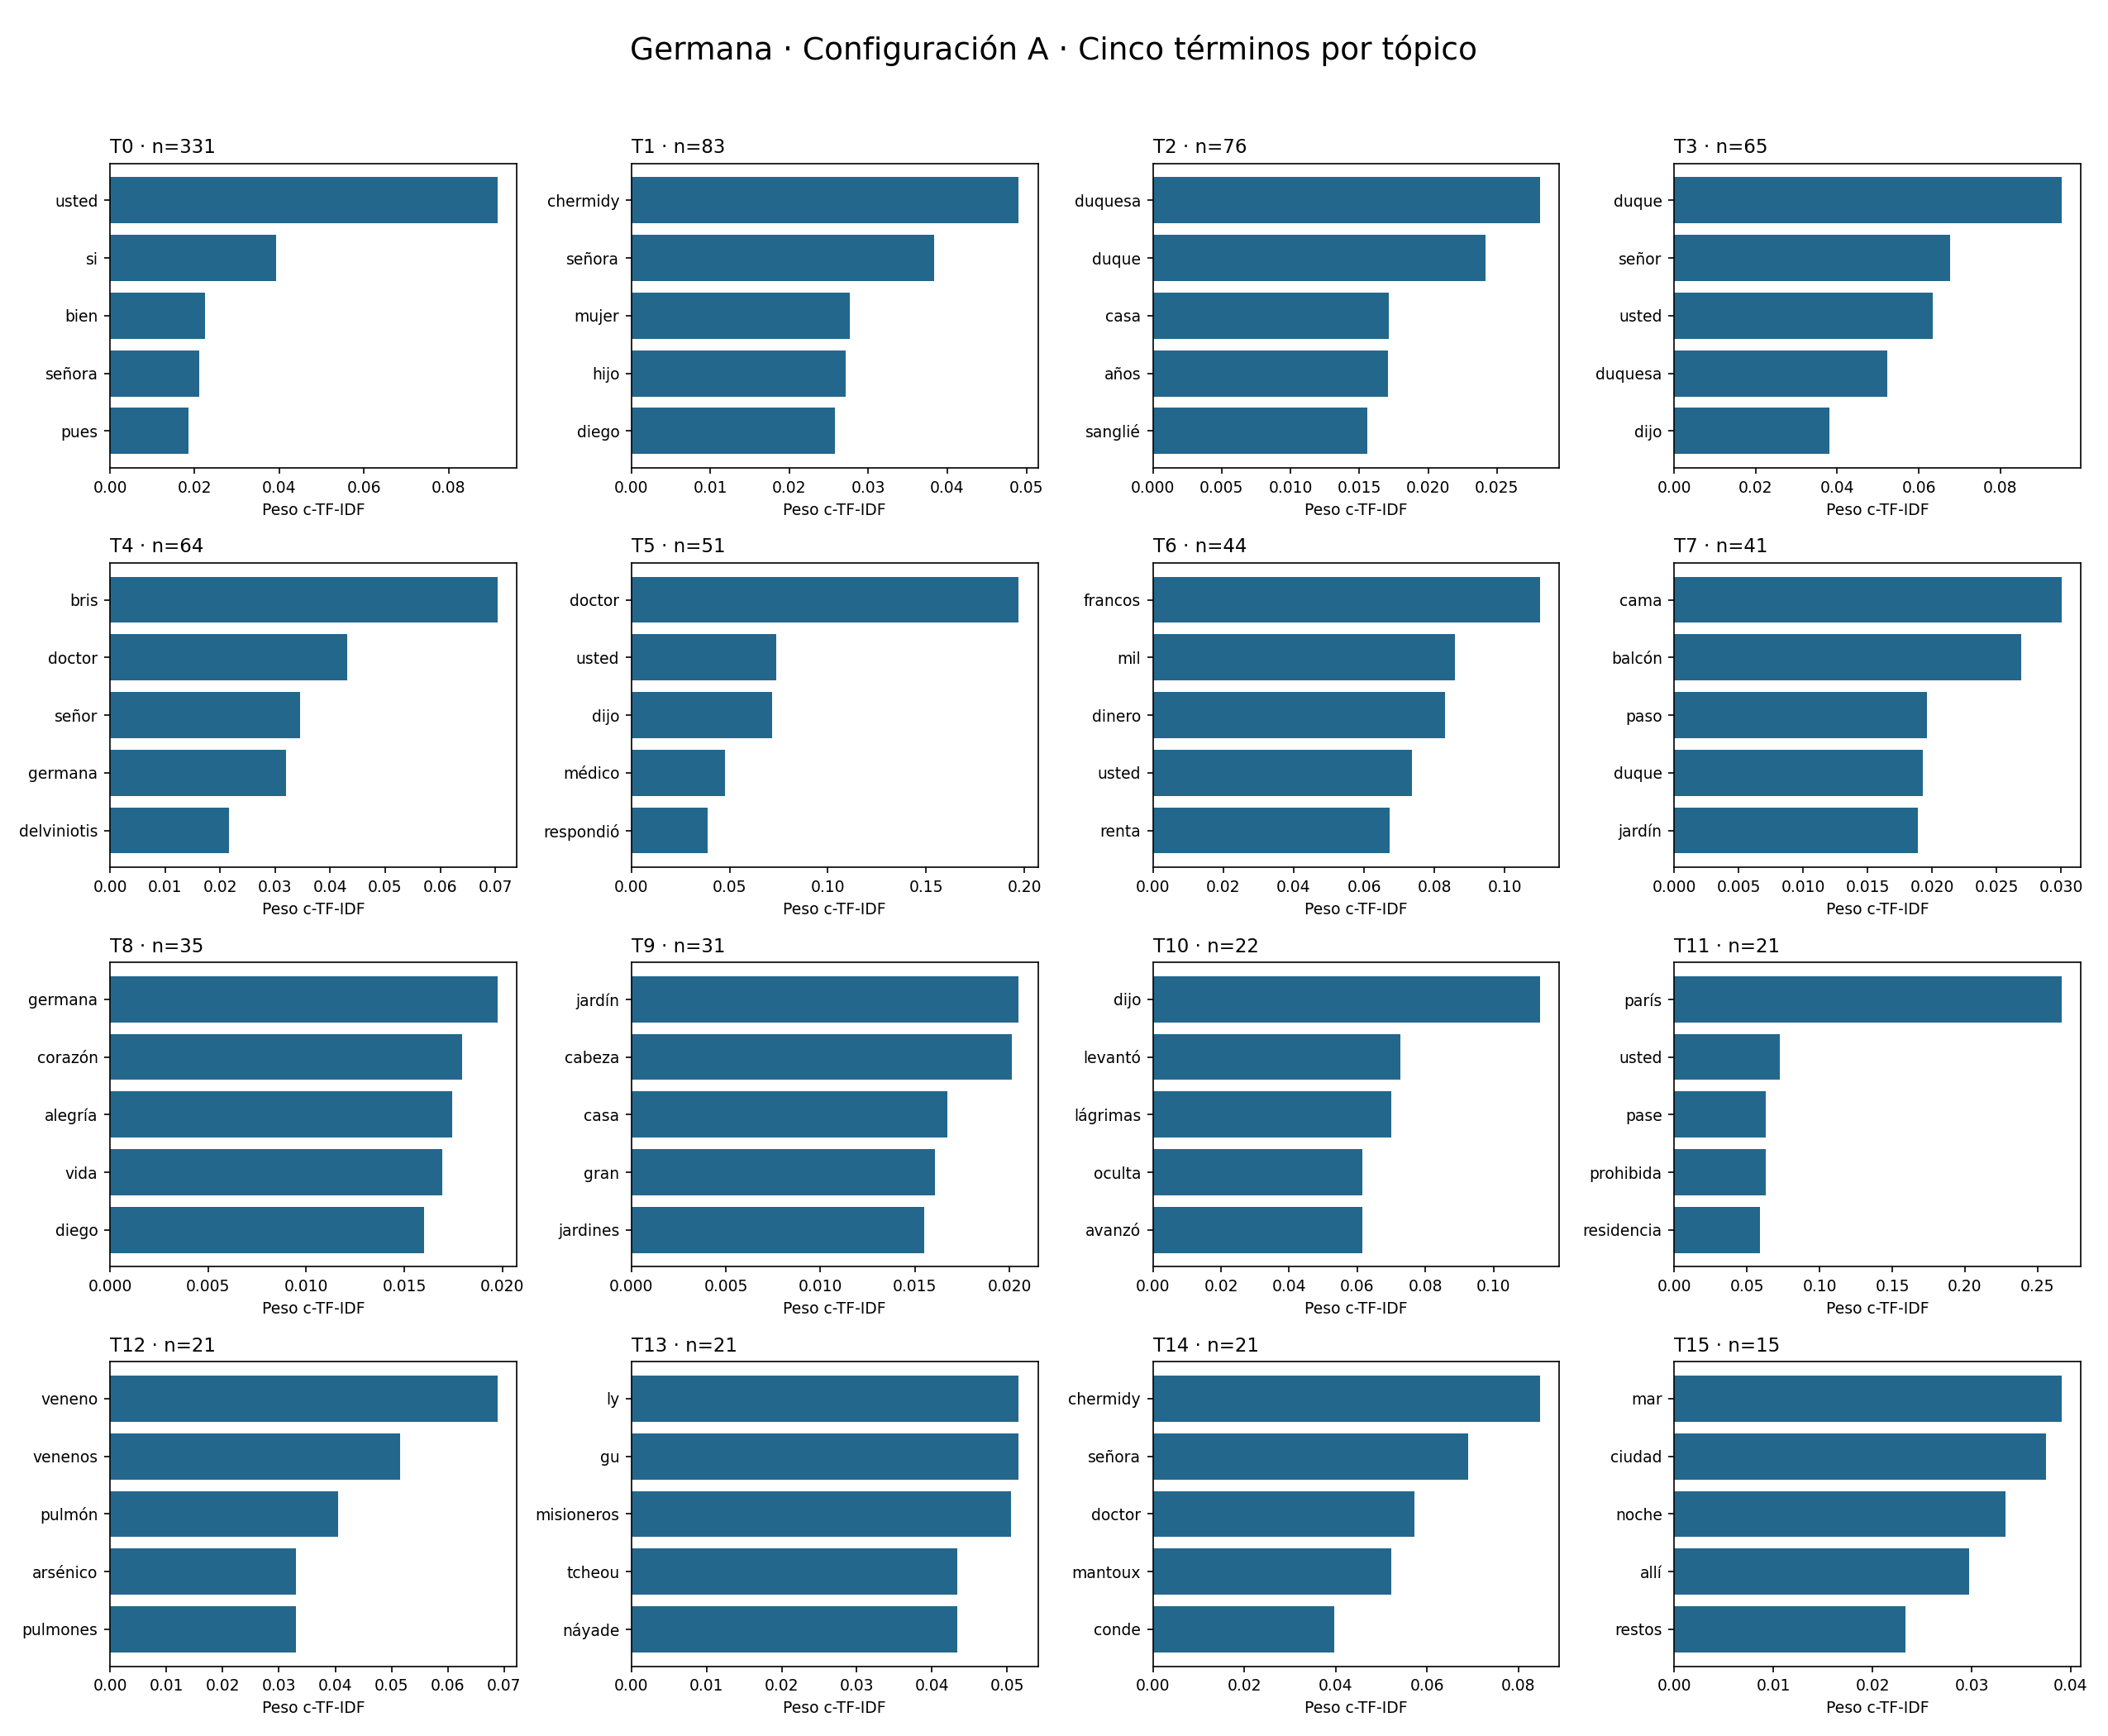

In [3]:
info = tables["A"].query("Topic >= 0")
# Reproduce los pesos con las clases oficiales y conserva el grupo -1.
from sklearn.feature_extraction.text import CountVectorizer
from bertopic.vectorizers import ClassTfidfTransformer
stop_es = (ROOT / "configuraciones" / "stopwords_es.txt").read_text().splitlines()
joined = df.groupby("topico_A", sort=True).texto.apply(lambda x: " ".join(x)).str.replace("\n", " ", regex=False).str.replace("\t", " ", regex=False)
vec = CountVectorizer(stop_words=stop_es, ngram_range=(1,1), min_df=1, strip_accents=None)
counts = vec.fit_transform(joined)
ctfidf = ClassTfidfTransformer().fit_transform(counts)
vocab = vec.get_feature_names_out()
fig, axes = plt.subplots(4, 4, figsize=(17, 14))
for ax, (_, row) in zip(axes.flat, info.iterrows()):
    pos = joined.index.get_loc(row.Topic)
    weights = ctfidf[pos].toarray().ravel()
    words = ast.literal_eval(row.Representation)[:5]
    idxs = [vec.vocabulary_[w] for w in words]
    ax.barh(words[::-1], weights[idxs][::-1], color="#24678d")
    ax.set_title(f"T{row.Topic} · n={row.Count}", loc="left", fontsize=11)
    ax.set_xlabel("Peso c-TF-IDF", fontsize=9)
    ax.tick_params(labelsize=9)
fig.suptitle("Germana · Configuración A · Cinco términos por tópico", fontsize=18)
fig.tight_layout(rect=(0,0,1,.96))
path = OUT / "01_palabras_topicos_A.png"
fig.savefig(path, dpi=150); plt.close(fig)
display(Image(filename=str(path)))


## Visualización 2: tamaño de los grupos y outliers

A produce 16 tópicos, pero su mayor grupo (0) contiene 331 párrafos: 28.12 % del corpus. En B y C el grupo 0 contiene 454: 38.57 %. Los grupos 0 y 1 de B/C suman 749 párrafos, 63.64 % del corpus, lo que evidencia una concentración en dos categorías muy amplias. A conserva mayor detalle; eso no convierte todos sus grupos pequeños en temas válidos. Los outliers suben de 235 (19.97 %) a 251 (21.33 %).


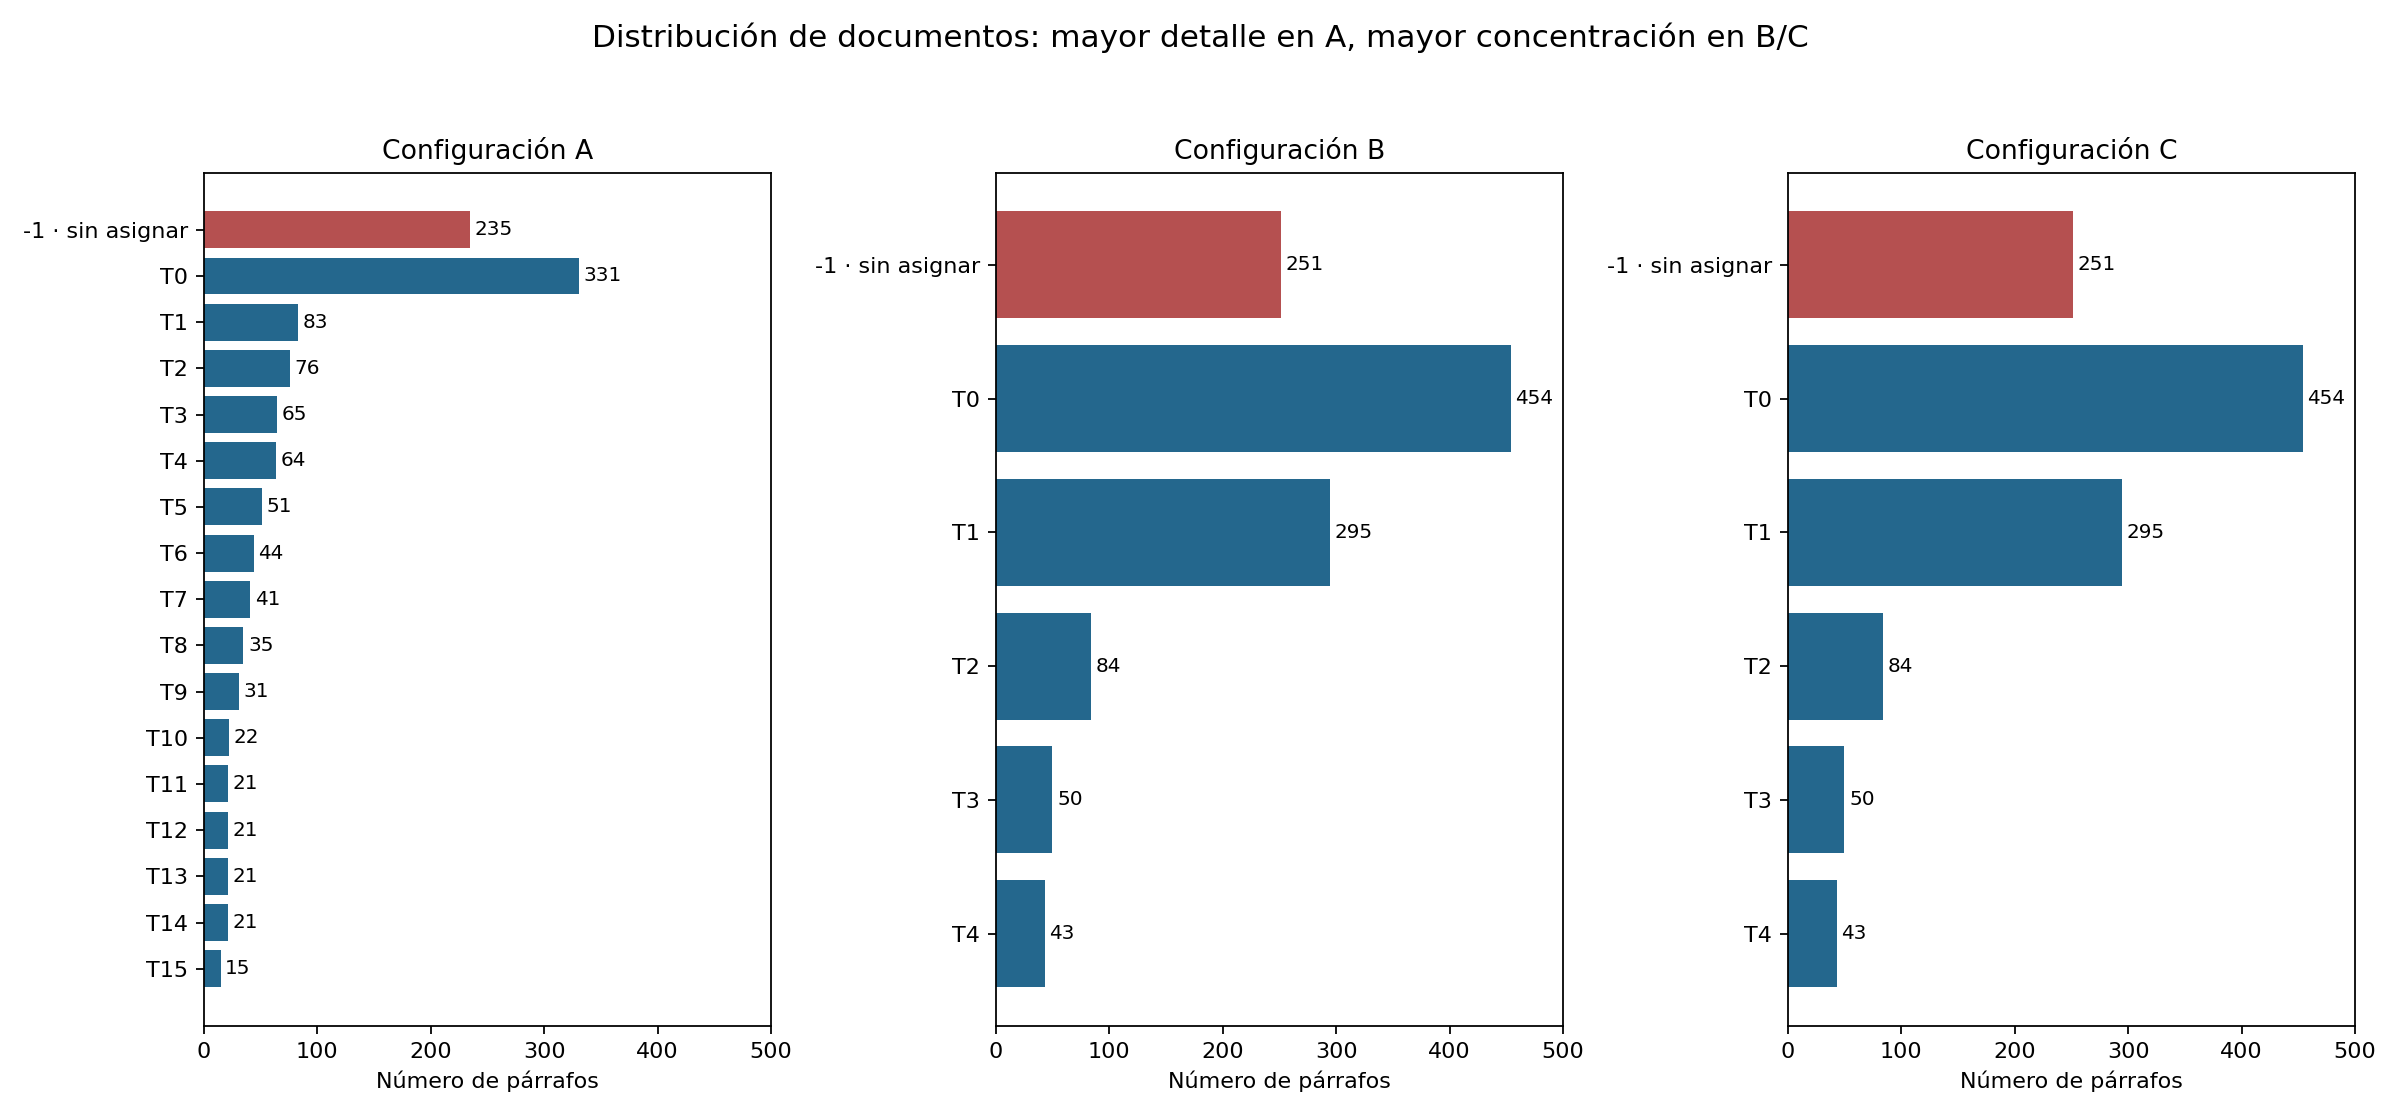

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 7))
for ax, config in zip(axes, ["A", "B", "C"]):
    tab = tables[config].sort_values("Topic")
    names = ["-1 · sin asignar" if t == -1 else f"T{t}" for t in tab.Topic]
    ax.barh(names, tab.Count, color=["#b55050" if t == -1 else "#24678d" for t in tab.Topic])
    ax.invert_yaxis(); ax.set_xlim(0, 500)
    ax.set_title(f"Configuración {config}")
    ax.set_xlabel("Número de párrafos")
    for i, n in enumerate(tab.Count): ax.text(n+4, i, str(n), va="center", fontsize=9)
fig.suptitle("Distribución de documentos: mayor detalle en A, mayor concentración en B/C", fontsize=14)
fig.tight_layout(rect=(0,0,1,.95))
path = OUT / "02_tamanos_y_outliers.png"
fig.savefig(path,dpi=160); plt.close(fig)
display(Image(filename=str(path)))


## Visualización 3: similitud entre centroides de A

Se promedian los embeddings originales de los documentos de cada tópico y se calcula el coseno entre esos centroides; no se usa la proyección de UMAP. Valores altos indican proximidad semántica media y no prueban equivalencia ni coherencia interna. La relación más alta aparece entre 7 (escenas de alcoba) y 8 (vida afectiva), aproximadamente 0.845; entre 1 (familia/legitimidad) y 8 es 0.832. Esto concuerda con el solapamiento entre enfermedad, emociones e intriga. No hay un umbral universal para decidir fusiones a partir de este gráfico.


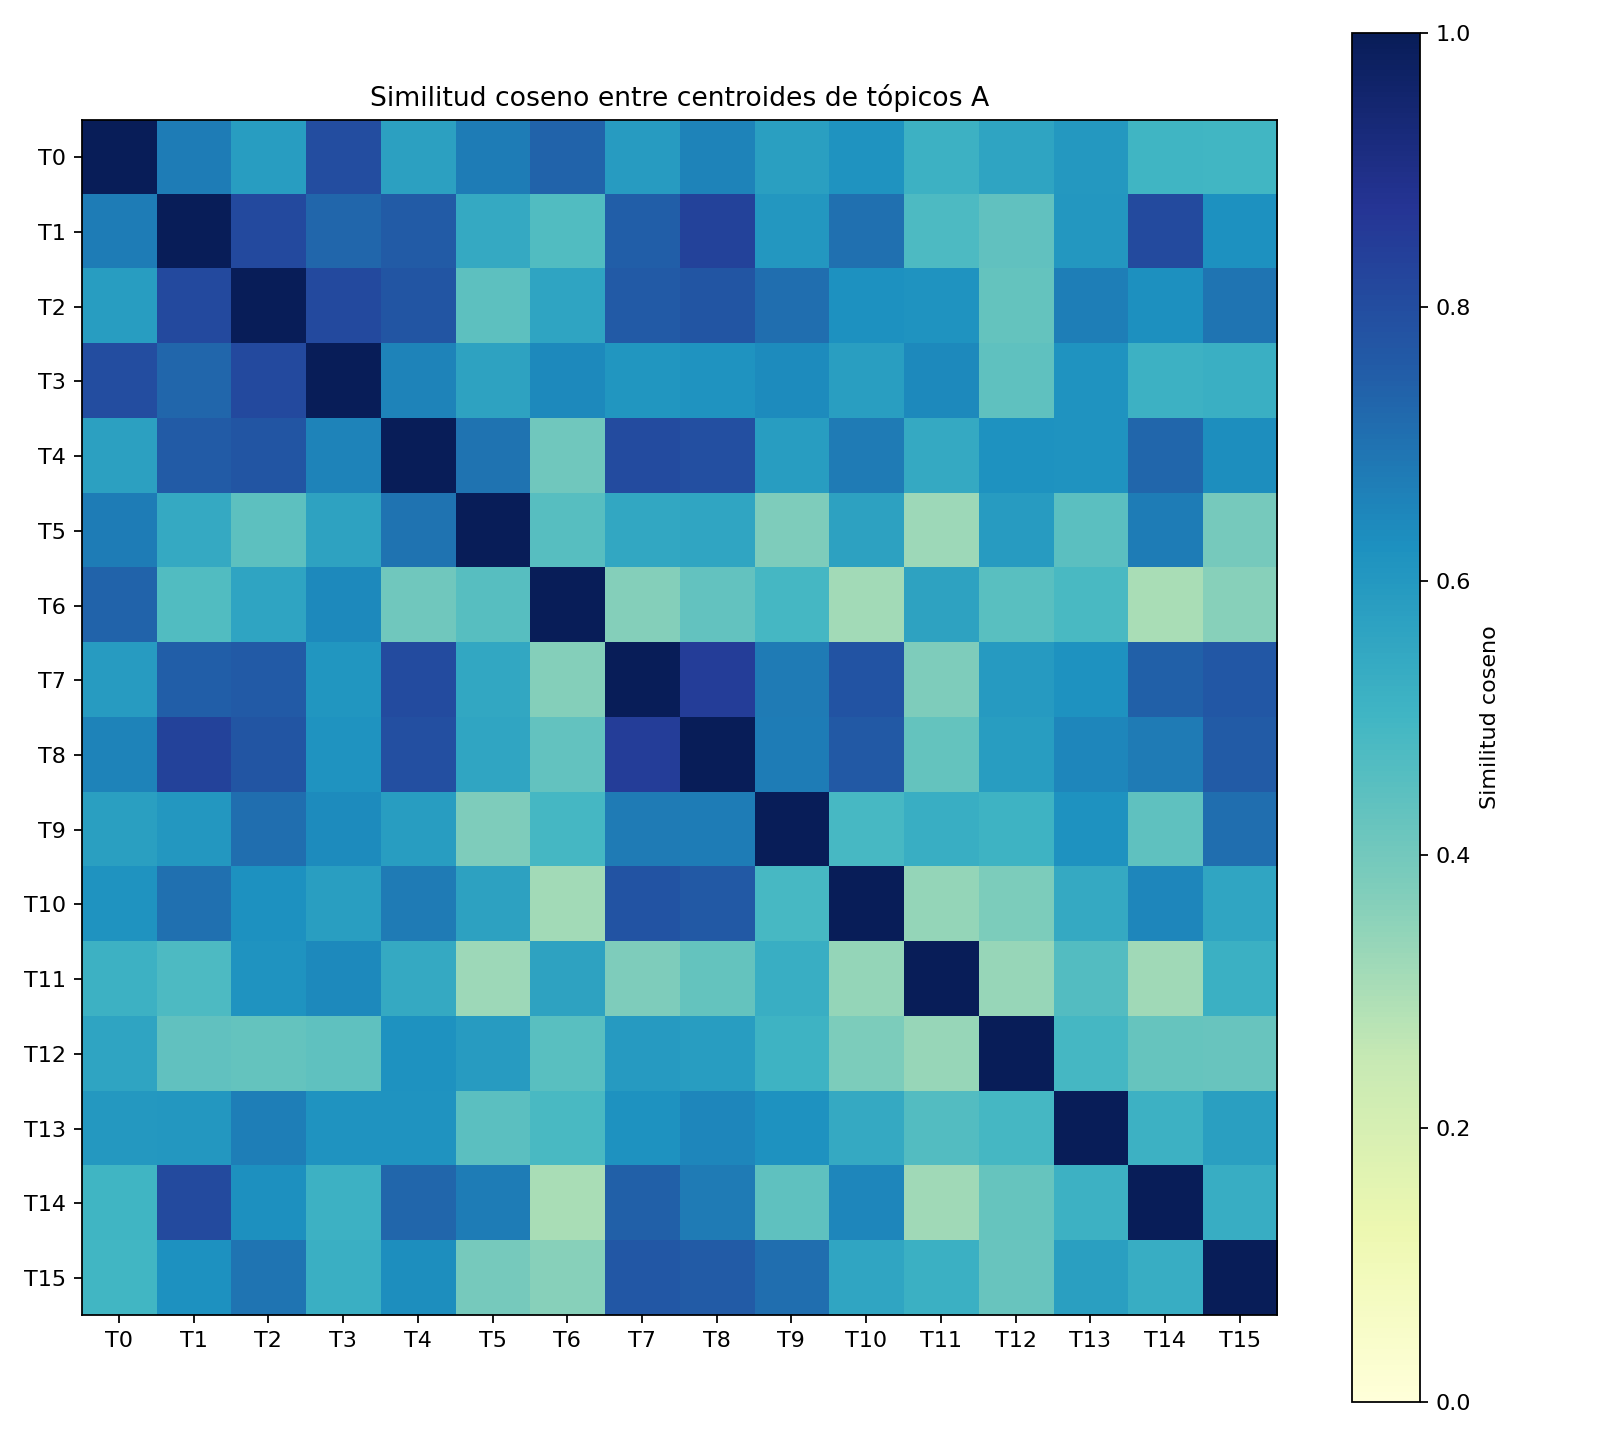

In [5]:
ids = sorted(set(df.topico_A) - {-1})
centroids = np.stack([embeddings[df.topico_A.to_numpy() == t].mean(axis=0) for t in ids])
sim = cosine_similarity(centroids)
pd.DataFrame(sim, index=ids, columns=ids).to_csv(OUT / "similitud_centroides_A.csv")
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(sim, vmin=0, vmax=1, cmap="YlGnBu")
ax.set_xticks(range(len(ids)), [f"T{t}" for t in ids])
ax.set_yticks(range(len(ids)), [f"T{t}" for t in ids])
ax.set_title("Similitud coseno entre centroides de tópicos A")
fig.colorbar(im, ax=ax, label="Similitud coseno")
fig.tight_layout()
path = OUT / "03_similitud_centroides_A.png"
fig.savefig(path,dpi=160); plt.close(fig)
display(Image(filename=str(path)))


## Comparación, outliers y límites

Se elige A como configuración principal para el análisis, con reservas. En B, 62 de los 64 documentos del tópico médico A4 y los 21 de A13 (China) pasan al grupo B0: la reducción de detalle mezcla episodios distintos. Los IDs no corresponden entre modelos: A0 se compara principalmente con B1, no con B0. La tabla de transición registra estas correspondencias sin suponer equivalencia por número.

C conserva exactamente las asignaciones de B. Los bigramas hacen aparecer expresiones como señora chermidy y señor duque, pero también doctor dijo; no se observa una mejora concluyente de coherencia temática. La diversidad top-10 pasa de 0.74 en B a 0.78 en C; esto mide variedad léxica, no coherencia. La de A es 0.7625 y no basta para ordenar la calidad de los modelos.

Los outliers se mantienen sin reasignar y sin descartarlos del análisis: 235/1177 en A y 251/1177 en B/C. La muestra de A incluye transiciones, conversaciones y descripciones que sí tienen sentido literario. La mediana de longitud de los outliers es 32 palabras, frente a 27 en los asignados: su condición no se explica solamente por ser demasiado breves. No se ejecuta reduce_outliers, porque forzar una pertenencia podría ocultar ambigüedades. Los conteos describen cobertura del modelo, no calidad del texto.

El 93.66 % de A0 empieza por --, mientras que A1 contiene un 15.66 % de inicios de diálogo. La prueba es un indicador simple de formato y no detecta todos los discursos directos. Sugiere que MiniLM y el agrupamiento distinguen estilo narrativo además de asuntos. Se conservaron las stopwords y configuraciones originales para evitar cambiar el experimento después de ver sus resultados.

Los representantes automáticos no prueban homogeneidad de todo un grupo. En A6 los dos primeros ejemplos son casi duplicados, aunque no son duplicados exactos: la redundancia puede reforzar artificialmente su aparente coherencia. Los promedios de embeddings de fragmentos conservan más contenido de los párrafos largos, pero pueden diluir asuntos distintos. Un solo libro comparte personajes y estilo, por lo que sus temas se solapan más que en una colección de noticias independientes.

Esta es una exploración de una sola semilla. No se midió estabilidad entre semillas ni coherencia con anotaciones humanas externas. Cambiar conjuntamente min_cluster_size y min_samples entre A y B no permite atribuir por separado sus efectos. No se presentan tiempos de ejecución como comparación de rendimiento, porque el primer ajuste puede incluir compilación y C solo actualiza la representación.

Conclusión: el modelo identifica núcleos reconocibles (dinero, atención médica, venenos y China) junto a categorías de interlocutor, escenario o estilo. A conserva mejor esos núcleos en esta comparación; sus 16 grupos no deben presentarse como 16 temas literarios igualmente válidos. Los nombres asignados describen la evidencia y señalan los grupos débiles.


In [6]:
# Guarda los casos revisados y crea un anexo con tres párrafos completos por tópico.
audit = []
for topic in ids:
    sample = df.loc[df.topico_A == topic].sample(2, random_state=17)
    for _, row in sample.iterrows():
        audit.append({"motivo": "muestra adicional A, semilla 17", "topico": topic,
                      "segmento_id": row.segmento_id, "texto": row.texto})
for _, row in df.loc[df.topico_A == -1].sample(10, random_state=42).iterrows():
    audit.append({"motivo": "muestra outliers A, semilla 42", "topico": -1,
                  "segmento_id": row.segmento_id, "texto": row.texto})
pd.DataFrame(audit).to_csv(OUT / "muestra_revision.csv",index=False)
lines = ["# Anexo: segmentos representativos completos", "",
         "Tres representantes automáticos por tópico. Los ejemplos de C son los mismos de B, porque C conserva sus grupos. Los números de tópico son locales a cada configuración.", ""]
for config in ["A", "B"]:
    lines += [f"## Configuración {config}" + (" (también C)" if config == "B" else ""), ""]
    for topic, rows in representatives[config].groupby("topico"):
        lines += [f"### T{topic}: {labels[config][str(topic)][0]}", ""]
        for _, row in rows.iterrows():
            lines += [f"**{row.segmento_id} · capítulo {row.capitulo} · {row.palabras} palabras**", "", row.texto, ""]
(OUT / "anexo_ejemplos.md").write_text("\n".join(lines))
print("Anexo y muestra de revisión guardados.")


Anexo y muestra de revisión guardados.


## Fuentes y declaración de IA

- Corpus y edición digital: https://www.gutenberg.org/ebooks/29640
- Modelo de embeddings: https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
- BERTopic: https://arxiv.org/abs/2203.05794
- Documentación de parámetros: https://maartengr.github.io/BERTopic/getting_started/parameter%20tuning/parametertuning.html
- Resultados locales: notebooks 01 y 02, topic_info.csv, ejemplos_representativos.csv, asignaciones.csv y metadatos.json.

Se utilizó Codex (OpenAI), el 25 de octubre de 2026, para implementar el análisis, proponer nombres de tópicos, revisar ejemplos y redactar la discusión. Los nombres son etiquetas interpretativas asistidas por IA; no son clases verdaderas ni una evaluación independiente. No se realizó el bonus, ninguna comparación con un LLM ni llamadas a una API de pago. La versión concreta del modelo de Codex no se registró. Las versiones de las librerías y la revisión exacta de MiniLM están registradas en los metadatos previos y requirements-lock.txt.
